#                         Customer Booking Analysis 

This notebook explores booking patterns, customer behavior, and data quality before preparing the final dataset for modeling.

## Objectives
- Understand the main booking features
- Inspect distributions and relationships
- Identify outliers and duplicate records
- Produce a cleaned dataset for modeling

> The charts in this notebook help explain which variables influence customer behavior and booking completion.

In [ ]:
# Import the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings   
# filter warnings   
warnings.filterwarnings("ignore")

In [ ]:
#Load data
df=pd.read_csv("customer_booking_UTF-8.csv")
df.head(10)

,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
0,2,Internet,RoundTrip,262,19,7,Sat,AKLDEL,New Zealand,1,0,0,5.52,0
1,1,Internet,RoundTrip,112,20,3,Sat,AKLDEL,New Zealand,0,0,0,5.52,0
2,2,Internet,RoundTrip,243,22,17,Wed,AKLDEL,India,1,1,0,5.52,0
3,1,Internet,RoundTrip,96,31,4,Sat,AKLDEL,New Zealand,0,0,1,5.52,0
4,2,Internet,RoundTrip,68,22,15,Wed,AKLDEL,India,1,0,1,5.52,0
5,1,Internet,RoundTrip,3,48,20,Thu,AKLDEL,New Zealand,1,0,1,5.52,0
6,3,Internet,RoundTrip,201,33,6,Thu,AKLDEL,New Zealand,1,0,1,5.52,0
7,2,Internet,RoundTrip,238,19,14,Mon,AKLDEL,India,1,0,1,5.52,0
8,1,Internet,RoundTrip,80,22,4,Mon,AKLDEL,New Zealand,0,0,1,5.52,0
9,1,Mobile,RoundTrip,378,30,12,Sun,AKLDEL,India,0,0,0,5.52,0


To provide more context, below is a more detailed data description, explaining exactly what each column means:

- `num_passengers` = number of passengers travelling
- `sales_channel` = sales channel booking was made on
- `trip_type` = trip Type (Round Trip, One Way, Circle Trip)
- `purchase_lead` = number of days between travel date and booking date
- `length_of_stay` = number of days spent at destination
- `flight_hour` = hour of flight departure
- `flight_day` = day of week of flight departure
- `route` = origin -> destination flight route
- `booking_origin` = country from where booking was made
- `wants_extra_baggage` = if the customer wanted extra baggage in the booking
- `wants_preferred_seat` = if the customer wanted a preferred seat in the booking
- `wants_in_flight_meals` = if the customer wanted in-flight meals in the booking
- `flight_duration` = total duration of flight (in hours)
- `booking_complete` = flag indicating if the customer completed the booking


In [42]:
df.shape

(50000, 14)

In [43]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   num_passengers         50000 non-null  int64  
 1   sales_channel          50000 non-null  object 
 2   trip_type              50000 non-null  object 
 3   purchase_lead          50000 non-null  int64  
 4   length_of_stay         50000 non-null  int64  
 5   flight_hour            50000 non-null  int64  
 6   flight_day             50000 non-null  object 
 7   route                  50000 non-null  object 
 8   booking_origin         50000 non-null  object 
 9   wants_extra_baggage    50000 non-null  int64  
 10  wants_preferred_seat   50000 non-null  int64  
 11  wants_in_flight_meals  50000 non-null  int64  
 12  flight_duration        50000 non-null  float64
 13  booking_complete       50000 non-null  int64  
dtypes: float64(1), int64(8), object(5)
memory usage: 5.3+ 

In [ ]:
# Transform flight_day column to numeric values
mapping = {
    "Mon": 1,
    "Tue": 2,
    "Wed": 3,
    "Thu": 4,
    "Fri": 5,
    "Sat": 6,
    "Sun": 7,
}

df["flight_day"] = df["flight_day"].map(mapping)

In [45]:
df.head()

,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
0,2,Internet,RoundTrip,262,19,7,6,AKLDEL,New Zealand,1,0,0,5.52,0
1,1,Internet,RoundTrip,112,20,3,6,AKLDEL,New Zealand,0,0,0,5.52,0
2,2,Internet,RoundTrip,243,22,17,3,AKLDEL,India,1,1,0,5.52,0
3,1,Internet,RoundTrip,96,31,4,6,AKLDEL,New Zealand,0,0,1,5.52,0
4,2,Internet,RoundTrip,68,22,15,3,AKLDEL,India,1,0,1,5.52,0


In [ ]:
# Describe data 
df.describe()

,num_passengers,purchase_lead,length_of_stay,flight_hour,flight_day,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
count,50000.000000,50000.000000,50000.00000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,1.591240,84.940480,23.04456,9.06634,3.814420,0.668780,0.296960,0.427140,7.277561,0.149560
std,1.020165,90.451378,33.88767,5.41266,1.992792,0.470657,0.456923,0.494668,1.496863,0.356643
min,1.000000,0.000000,0.00000,0.00000,1.000000,0.000000,0.000000,0.000000,4.670000,0.000000
25%,1.000000,21.000000,5.00000,5.00000,2.000000,0.000000,0.000000,0.000000,5.620000,0.000000
50%,1.000000,51.000000,17.00000,9.00000,4.000000,1.000000,0.000000,0.000000,7.570000,0.000000
75%,2.000000,115.000000,28.00000,13.00000,5.000000,1.000000,1.000000,1.000000,8.830000,0.000000
max,9.000000,867.000000,778.00000,23.00000,7.000000,1.000000,1.000000,1.000000,9.500000,1.000000


### Let's analyse each feature:

### Number of Passengers

In [47]:
df["num_passengers"].value_counts()

1    31352
2    12804
3     2941
4     1784
5      561
6      289
7      114
8       89
9       66
Name: num_passengers, dtype: int64

In [48]:
px.histogram(df,x="num_passengers",nbins=9,color="num_passengers",
             title="The ditribution of number of passengers")

The count of passengers decrease as the number of passengers increase.

In [49]:
px.box(df,y="num_passengers")

## sales channel

In [50]:
df["sales_channel"].value_counts()
px.pie(df,names="sales_channel",width=350,height=350)

### Trip Type

In [51]:
df["trip_type"].value_counts()
px.pie(df,names="trip_type",width=450,height=450,
      color_discrete_sequence=["gray","red","green"])

### Purchase lead

In [52]:
px.violin(df["purchase_lead"])

In [53]:
px.histogram(df.purchase_lead)

### Length of stay

In [54]:
px.box(df.length_of_stay)

In [55]:
px.histogram(df.length_of_stay)

### Flight hour

In [56]:
px.box(df.flight_hour,color_discrete_sequence=["red"],
      title="The distribution of flight hours",width=550,height=450)

In [57]:
px.histogram(df.flight_hour,nbins=24)# color=df.flight_hour)

### Flight day

In [58]:
px.box(df.flight_day)

In [59]:
px.histogram(df,x="flight_day")

### Route

Text(0, 0.5, 'Count')

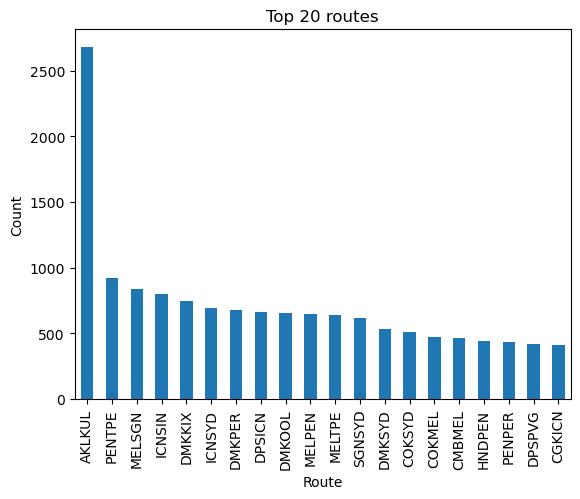

In [60]:
df.route.value_counts()[:20].plot(kind="bar")
plt.title("Top 20 routes")
plt.xlabel("Route")
plt.ylabel("Count")

### Booking origin

<Axes: xlabel='booking_origin', ylabel='count'>

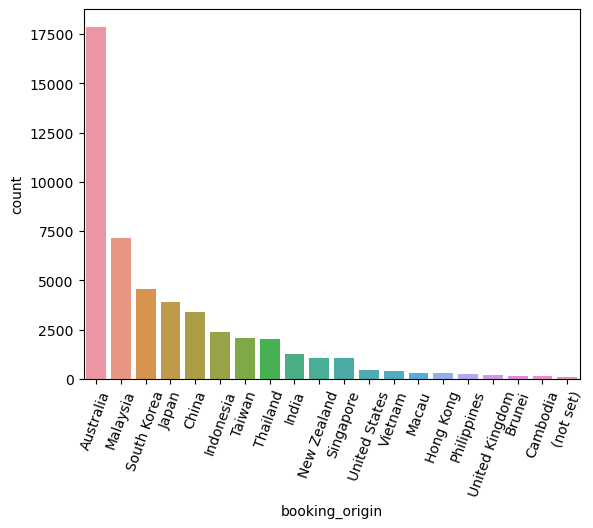

In [61]:
top20_origins=df.booking_origin.value_counts()[0:20].to_frame()
top20_origins=top20_origins.reset_index().rename(columns={"index":"booking_origin","booking_origin":"count"})

plt.xticks(rotation=70)
sns.barplot(top20_origins,x=top20_origins["booking_origin"],y=top20_origins["count"])


In [62]:
px.pie(df,names=df.wants_extra_baggage,labels=["Yes","No"],
       hover_data=['length_of_stay'],hole=0.5)

In [63]:
df.head()

,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
0,2,Internet,RoundTrip,262,19,7,6,AKLDEL,New Zealand,1,0,0,5.52,0
1,1,Internet,RoundTrip,112,20,3,6,AKLDEL,New Zealand,0,0,0,5.52,0
2,2,Internet,RoundTrip,243,22,17,3,AKLDEL,India,1,1,0,5.52,0
3,1,Internet,RoundTrip,96,31,4,6,AKLDEL,New Zealand,0,0,1,5.52,0
4,2,Internet,RoundTrip,68,22,15,3,AKLDEL,India,1,0,1,5.52,0


In [64]:
px.pie(df,names=df.	wants_preferred_seat,labels=["Yes","No"],
       hover_data=['length_of_stay'],hole=0.5)

In [65]:
px.pie(df,names=df.wants_in_flight_meals,labels=["Yes","No"],
       hover_data=['length_of_stay'],hole=0.5)

### Flight duration

In [66]:
px.box(df.flight_duration,width=400,height=450)

In [67]:
px.histogram(df.flight_duration,width=600,height=500)

In [68]:
px.pie(names=df.booking_complete,hole=0.6,color_discrete_sequence=["#A2C579","#D2DE32"])

## let's look at the correlation between the numerical features:

<Axes: >

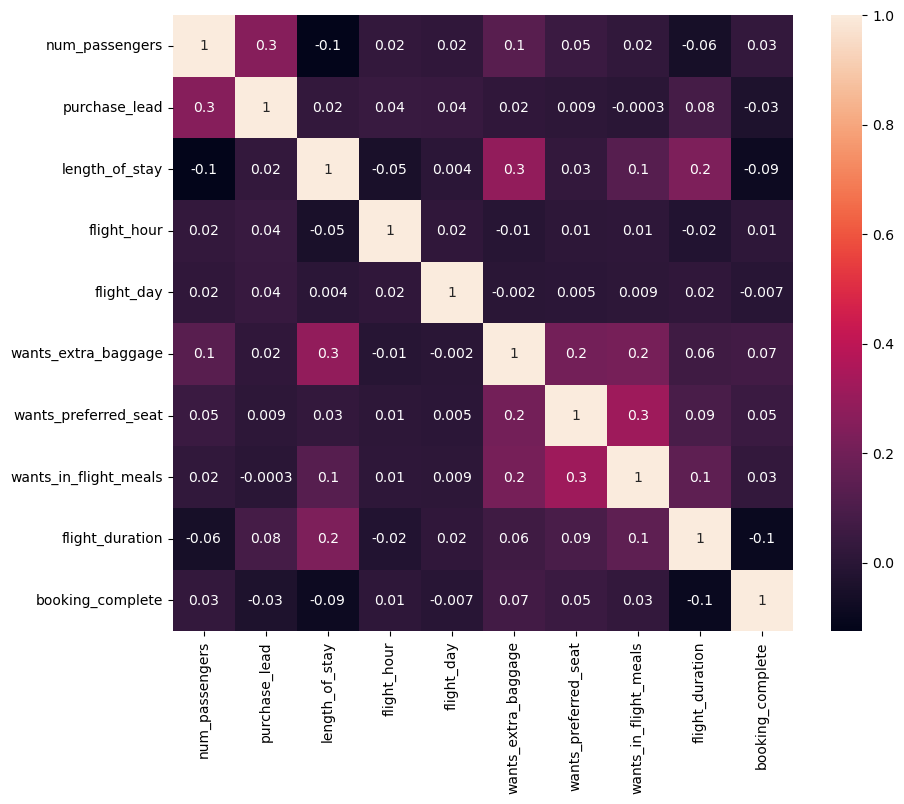

In [69]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr("spearman"),annot=True,fmt='.1g')

In [70]:
categorical_features=['sales_channel', 'trip_type','route','booking_origin']
df[categorical_features].head()

,sales_channel,trip_type,route,booking_origin
0,Internet,RoundTrip,AKLDEL,New Zealand
1,Internet,RoundTrip,AKLDEL,New Zealand
2,Internet,RoundTrip,AKLDEL,India
3,Internet,RoundTrip,AKLDEL,New Zealand
4,Internet,RoundTrip,AKLDEL,India


In [71]:
for feature in categorical_features:
    ax=px.histogram(df, x=feature, color="booking_complete")
    ax.show()

In [ ]:
df[]

# Handling Outliers:

In [72]:
df["booking_complete"]

,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
0,2,Internet,RoundTrip,262,19,7,6,AKLDEL,New Zealand,1,0,0,5.52,0
1,1,Internet,RoundTrip,112,20,3,6,AKLDEL,New Zealand,0,0,0,5.52,0
2,2,Internet,RoundTrip,243,22,17,3,AKLDEL,India,1,1,0,5.52,0
3,1,Internet,RoundTrip,96,31,4,6,AKLDEL,New Zealand,0,0,1,5.52,0
4,2,Internet,RoundTrip,68,22,15,3,AKLDEL,India,1,0,1,5.52,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,2,Internet,RoundTrip,27,6,9,6,PERPNH,Australia,1,0,1,5.62,0
49996,1,Internet,RoundTrip,111,6,4,7,PERPNH,Australia,0,0,0,5.62,0
49997,1,Internet,RoundTrip,24,6,22,6,PERPNH,Australia,0,0,1,5.62,0
49998,1,Internet,RoundTrip,15,6,11,1,PERPNH,Australia,1,0,1,5.62,0


# Local Outlier Factor:

In [73]:
data_with_outliers=df[['num_passengers', 'purchase_lead',
       'length_of_stay']]

In [89]:
import numpy as np
from sklearn.neighbors import LocalOutlierFactor

# Sample dataset
"""data = np.array([[0.0001, 2.0],
                 [1.5, 2.5],
                 [3.0, 3.0],
                 [10.0, 10.0],
                 [110.0, 11.0]])
"""
data=np.array(data_with_outliers)


# Specify LOF parameters
n_neighbors = 7  # Number of neighbors to consider (you can adjust this)
contamination = 0.4 # Expected proportion of outliers in the dataset (you can adjust this)

# Create an LOF model
lof = LocalOutlierFactor(n_neighbors=n_neighbors, contamination=contamination)

# Fit the model to the data and obtain outlier scores
outlier_scores = lof.fit_predict(data)

# Identify the indices of the outliers (negative scores are outliers)
outlier_indices = np.where(outlier_scores == -1)[0]

# Remove outliers from the dataset
clean_data = np.delete(data, outlier_indices, axis=0)

# Print the cleaned dataset and the removed outliers
print("Original dataset:")
print(data)
print("\nCleaned dataset:")
print(clean_data)
print("\nOutliers removed:")

print(data[outlier_indices])
print(outlier_indices)

Original dataset:
[[  2 262  19]
 [  1 112  20]
 [  2 243  22]
 ...
 [  1  24   6]
 [  1  15   6]
 [  1  19   6]]

Cleaned dataset:
[[  2 262  19]
 [  1 112  20]
 [  2 243  22]
 ...
 [  1  24   6]
 [  1  15   6]
 [  1  19   6]]

Outliers removed:
[[  1  96  31]
 [  2  68  22]
 [  3 201  33]
 ...
 [  4 242   6]
 [  1 112   6]
 [  3 243   6]]
[    3     4     6 ... 49980 49983 49987]


In [90]:
new_df=df.drop(index=outlier_indices)
new_df.shape

(33049, 14)

In [97]:
px.histogram(new_df["num_passengers"])
new_df=new_df[new_df["num_passengers"]<=5]

In [92]:
df.columns

Index(['num_passengers', 'sales_channel', 'trip_type', 'purchase_lead',
       'length_of_stay', 'flight_hour', 'flight_day', 'route',
       'booking_origin', 'wants_extra_baggage', 'wants_preferred_seat',
       'wants_in_flight_meals', 'flight_duration', 'booking_complete'],
      dtype='object')

In [103]:
px.box(new_df["length_of_stay"])
px.histogram(new_df["length_of_stay"])
new_df=new_df[new_df["length_of_stay"]<90]

In [107]:
px.box(new_df["purchase_lead"])
px.histogram(new_df["purchase_lead"])
new_df=new_df[new_df["purchase_lead"]<450]

## Drop Duplicates 

In [115]:
new_df[new_df.duplicated()].shape

(530, 14)

In [118]:
new_df=new_df.drop_duplicates()

## Data Formating

In [123]:
new_df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 31908 entries, 0 to 49999
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   num_passengers         31908 non-null  int64  
 1   sales_channel          31908 non-null  object 
 2   trip_type              31908 non-null  object 
 3   purchase_lead          31908 non-null  int64  
 4   length_of_stay         31908 non-null  int64  
 5   flight_hour            31908 non-null  int64  
 6   flight_day             31908 non-null  int64  
 7   route                  31908 non-null  object 
 8   booking_origin         31908 non-null  object 
 9   wants_extra_baggage    31908 non-null  int64  
 10  wants_preferred_seat   31908 non-null  int64  
 11  wants_in_flight_meals  31908 non-null  int64  
 12  flight_duration        31908 non-null  float64
 13  booking_complete       31908 non-null  int64  
dtypes: float64(1), int64(9), object(4)
memory usage: 3.7+ 

In [ ]:
new_df.to_csv("Custmer Booking clean data.csv")

## Final output summary

- Most bookings are for a small number of passengers.
- Sales channel and travel-pattern distributions show where demand is strongest.
- The booking-complete chart is the main business indicator for conversion performance.
- Correlation analysis helps identify the strongest feature relationships.
- Outlier and duplicate removal improve data quality before modeling.
- The cleaned dataset is ready for the next stage of analysis and model training.